In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load all three datasets once
wine = pd.read_csv('wine (1).csv')
chickwts = pd.read_csv('chickwts.csv')
usarrests = pd.read_csv('USArrests.csv')

# Check for missing values across datasets
print("Wine Missing Values:", wine.isnull().sum().sum())
print("Chickwts Missing Values:", chickwts.isnull().sum().sum())
print("USArrests Missing Values:", usarrests.isnull().sum().sum())

# Standardize numerical features for machine learning readiness
scaler = StandardScaler()
wine_scaled = scaler.fit_transform(wine.drop(columns=['target']))
chickwts['weight_scaled'] = scaler.fit_transform(chickwts[['weight']])
numeric_cols = usarrests.select_dtypes(include=[np.number]).columns
usarrests[numeric_cols] = scaler.fit_transform(usarrests[numeric_cols])

Wine Missing Values: 0
Chickwts Missing Values: 0
USArrests Missing Values: 0


In [4]:
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Separate features and target labels from the wine dataset
X = wine.drop(columns=['target'])
y = wine['target']

# Scale the feature matrix
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA retaining 95% variance
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Define parameter grid for k-NN tuning
param_grid = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Perform 5-fold grid search
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid.fit(X_pca, y)

# Split data into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Train and evaluate the best estimator
best_knn = grid.best_estimator_
best_knn.fit(X_train, y_train)
y_pred = best_knn.predict(X_test)

print("Best Parameters:", grid.best_params_)
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Best Parameters: {'metric': 'euclidean', 'n_neighbors': 11}
Accuracy Score: 0.9444444444444444

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       1.00      0.86      0.92        14
           2       0.89      1.00      0.94         8

    accuracy                           0.94        36
   macro avg       0.94      0.95      0.94        36
weighted avg       0.95      0.94      0.94        36



In [6]:
from sklearn.metrics.pairwise import cosine_similarity

# Standardize the weight feature and reduce dimensionality to 1 principal component
chickwts['weight_scaled'] = StandardScaler().fit_transform(chickwts[['weight']])
chickwts['weight_pca'] = PCA(n_components=1, random_state=42).fit_transform(chickwts[['weight_scaled']])

# Group by feed type to calculate mean PCA weight per category
feed_summary = chickwts.groupby('feed')['weight_pca'].mean().reset_index()

# Compute cosine similarity between feed types based on the PCA component
similarity_matrix = cosine_similarity(feed_summary[['weight_pca']])
similarity_df = pd.DataFrame(similarity_matrix, index=feed_summary['feed'], columns=feed_summary['feed'])

print("Feed Summary:")
print(feed_summary)
print("\nCosine Similarity Matrix:")
print(similarity_df)

Feed Summary:
        feed  weight_pca
0     casein    0.803301
1  horsebean   -1.304274
2    linseed   -0.549004
3   meatmeal    0.201223
4    soybean   -0.191962
5  sunflower    0.872099

Cosine Similarity Matrix:
feed       casein  horsebean  linseed  meatmeal  soybean  sunflower
feed                                                               
casein        1.0       -1.0     -1.0       1.0     -1.0        1.0
horsebean    -1.0        1.0      1.0      -1.0      1.0       -1.0
linseed      -1.0        1.0      1.0      -1.0      1.0       -1.0
meatmeal      1.0       -1.0     -1.0       1.0     -1.0        1.0
soybean      -1.0        1.0      1.0      -1.0      1.0       -1.0
sunflower     1.0       -1.0     -1.0       1.0     -1.0        1.0


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


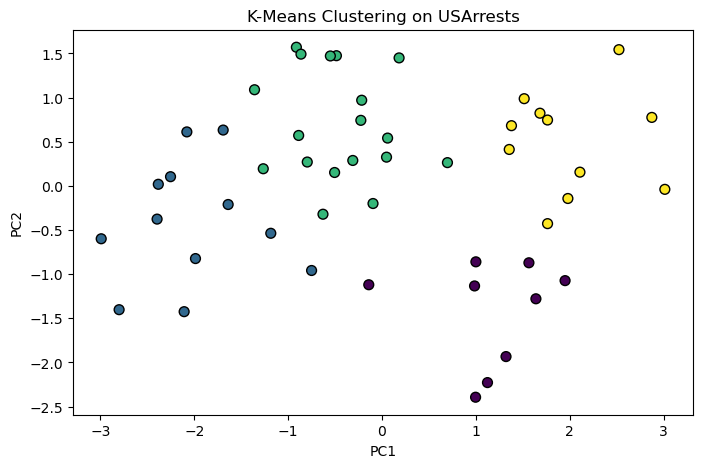

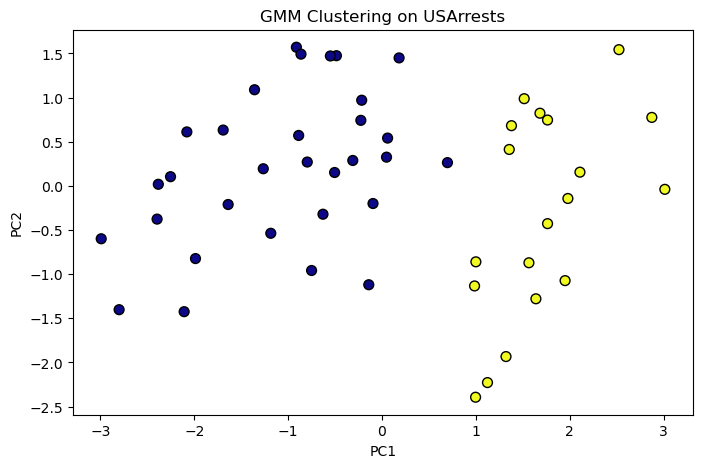

In [8]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Select numerical features and standardize them
numeric_data = usarrests.drop(columns=['rownames'])
scaled_data = StandardScaler().fit_transform(numeric_data)

# Reduce dimensions to 2 principal components using PCA
pca_data = PCA(n_components=2, random_state=42).fit_transform(scaled_data)

# Fit K-Means (4 clusters) and GMM (2 components)
usarrests['kmeans_cluster'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(pca_data)
usarrests['gmm_cluster'] = GaussianMixture(n_components=2, random_state=42).fit_predict(pca_data)

# Visualize and save K-Means clusters
plt.figure(figsize=(8, 5))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=usarrests['kmeans_cluster'], cmap='viridis', s=50, edgecolor='k')
plt.title('K-Means Clustering on USArrests')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('kmeans_plot.png')
plt.show()
plt.close()

# Visualize and save GMM clusters
plt.figure(figsize=(8, 5))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=usarrests['gmm_cluster'], cmap='plasma', s=50, edgecolor='k')
plt.title('GMM Clustering on USArrests')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('gmm_plot.png')
plt.show()
plt.close()